**Mathematics for Artificial Intelligence**  
**Topic:** Interpolation

**Authors:** Luis David Gonzalez Romero and Diego Alberto Ortega Carreto  
**Instructor:** Dr. Francisco Rafael Trejo Macotela  
**Submission date:** November 16, 2026

In [49]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display

x_symbol = sp.symbols("x")

In [50]:
datasets = {
    "Exercise 1": [(2, 5), (6, 13)],
    "Exercise 2": [(1, 4), (6, 19)],
    "Exercise 3": [(0, 2), (5, 17)],
    "Exercises 4 and 7": [(0, 1), (1, 3), (2, 7)],
    "Exercises 5 and 8": [(0, 2), (1, 5), (2, 4)],
    "Exercises 6 and 9": [(0, 3), (1, 2), (3, 6)],
    "Exercise 10": [(0, 0), (1, 1), (2, 8), (3, 27)],
    "Exercise 11": [(0, 1), (1, 3), (2, 7), (3, 10)],
}
normalized = datasets

In [44]:
def rational_points(points):
    return [(sp.Rational(str(x)), sp.Rational(str(y))) for x, y in points]

def lagrange_basis(points):
    exact = rational_points(points)
    return [
        sp.factor(sp.prod((x_symbol - xj) / (xi - xj) for j, (xj, _) in enumerate(exact) if i != j))
        for i, (xi, _) in enumerate(exact)
    ]

def lagrange_polynomial(points):
    exact = rational_points(points)
    bases = lagrange_basis(points)
    polynomial = sp.expand(sum(yi * basis for (_, yi), basis in zip(exact, bases)))
    return polynomial, bases

def lagrange_evaluate(points, value):
    exact = rational_points(points)
    value = sp.Rational(str(value))
    total = sp.Integer(0)
    for i, (xi, yi) in enumerate(exact):
        basis_value = sp.prod((value - xj) / (xi - xj) for j, (xj, _) in enumerate(exact) if i != j)
        total += yi * basis_value
    return sp.simplify(total)

def divided_difference_table(points):
    exact = rational_points(points)
    count = len(exact)
    table = [[None] * count for _ in range(count)]
    for i, (_, yi) in enumerate(exact):
        table[i][0] = yi
    for order in range(1, count):
        for row in range(count - order):
            table[row][order] = sp.simplify(
                (table[row + 1][order - 1] - table[row][order - 1])
                / (exact[row + order][0] - exact[row][0])
            )
    return exact, table

def newton_polynomial(points):
    exact, table = divided_difference_table(points)
    polynomial = sp.Integer(0)
    term = sp.Integer(1)
    for order, (xi, _) in enumerate(exact):
        polynomial += table[0][order] * term
        term *= x_symbol - xi
    return sp.expand(polynomial), table

def newton_evaluate(points, value):
    exact, table = divided_difference_table(points)
    value = sp.Rational(str(value))
    total = sp.Integer(0)
    term = sp.Integer(1)
    for order, (xi, _) in enumerate(exact):
        total += table[0][order] * term
        term *= value - xi
    return sp.simplify(total)

def display_difference_table(exercise, points, table=None):
    if table is None:
        _, table = divided_difference_table(points)
    exact = rational_points(points)
    columns = ["x", "f[x]"] + [f"Order {order}" for order in range(1, len(exact))]
    rows = [
        [str(xi)] + ["" if table[row][order] is None else str(table[row][order]) for order in range(len(exact))]
        for row, (xi, _) in enumerate(exact)
    ]
    result = pd.DataFrame(rows, columns=columns)
    result.insert(0, "Exercise", exercise)
    display(result)
    return table

## Exercise 7: Newton divided differences

For the nodes $(0,1)$, $(1,3)$, and $(2,7)$, build the divided-difference table and Newton polynomial. Estimate at $x=1.5$ and compare with Exercise 4.

The Newton and Lagrange interpolants must coincide because both have degree at most two and pass through the same three distinct nodes. Uniqueness of the interpolating polynomial therefore forces them to be identical.

,Slope,Line,Target x,Estimate
0,2,2*x + 1,4,9


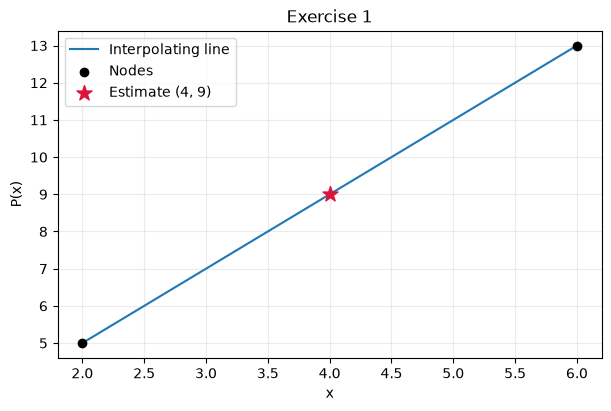

In [51]:
points = datasets["Exercise 1"]
target = 4
(x0, y0), (x1, y1) = points
slope = sp.Rational(y1 - y0, x1 - x0)
intercept = y0 - slope * x0
line = sp.expand(slope * x_symbol + intercept)
estimate = sp.simplify(line.subs(x_symbol, target))
assert slope * (x1 - x0) + y0 == y1
assert estimate == y0 + slope * (target - x0)
display(pd.DataFrame([{"Slope": slope, "Line": line, "Target x": target, "Estimate": estimate}]))

x_values = np.linspace(x0, x1, 200)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(line.subs(x_symbol, value)) for value in x_values], label="Interpolating line")
ax.scatter([x0, x1], [y0, y1], color="black", label="Nodes", zorder=3)
ax.scatter([target], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 1", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 2: Linear interpolation

Given $(1,4)$ and $(6,19)$, find the slope and line, then estimate the function value at $x=4$.

,Slope,Line,Target x,Estimate
0,3,3*x + 1,4,13


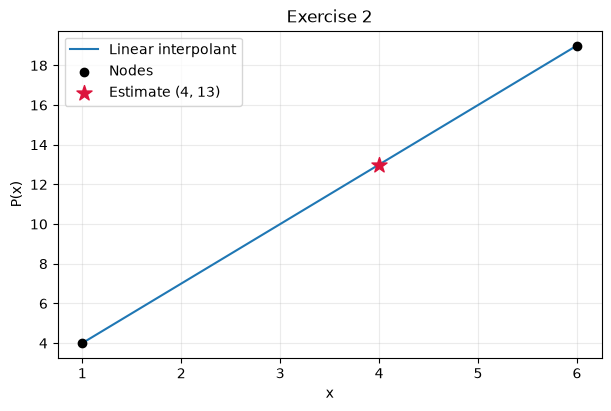

In [52]:
points = datasets["Exercise 2"]
target = 4
(x0, y0), (x1, y1) = points
slope = sp.Rational(y1 - y0, x1 - x0)
intercept = y0 - slope * x0
line = sp.expand(slope * x_symbol + intercept)
estimate = sp.simplify(line.subs(x_symbol, target))
assert slope * (x1 - x0) + y0 == y1
assert estimate == y0 + slope * (target - x0)
display(pd.DataFrame([{"Slope": slope, "Line": line, "Target x": target, "Estimate": estimate}]))

x_values = np.linspace(x0, x1, 200)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(line.subs(x_symbol, value)) for value in x_values], label="Linear interpolant")
ax.scatter([x0, x1], [y0, y1], color="black", label="Nodes", zorder=3)
ax.scatter([target], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 2", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 3: Linear interpolation

Given $(0,2)$ and $(5,17)$, find the slope and line, then estimate the function value at $x=3$.

,Slope,Line,Target x,Estimate
0,3,3*x + 2,3,11


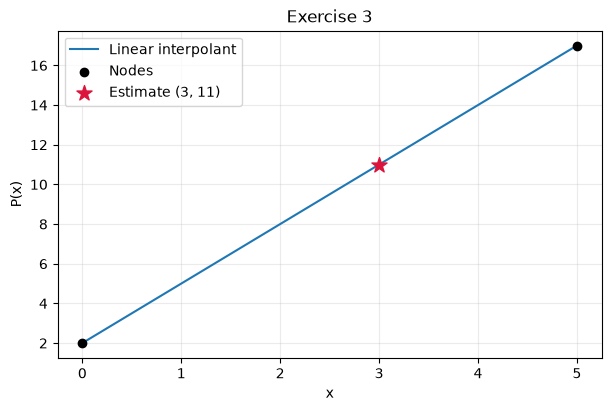

In [53]:
points = datasets["Exercise 3"]
target = 3
(x0, y0), (x1, y1) = points
slope = sp.Rational(y1 - y0, x1 - x0)
intercept = y0 - slope * x0
line = sp.expand(slope * x_symbol + intercept)
estimate = sp.simplify(line.subs(x_symbol, target))
assert slope * (x1 - x0) + y0 == y1
assert estimate == y0 + slope * (target - x0)
display(pd.DataFrame([{"Slope": slope, "Line": line, "Target x": target, "Estimate": estimate}]))

x_values = np.linspace(x0, x1, 200)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(line.subs(x_symbol, value)) for value in x_values], label="Linear interpolant")
ax.scatter([x0, x1], [y0, y1], color="black", label="Nodes", zorder=3)
ax.scatter([target], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 3", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 4: Lagrange interpolation

For the nodes $(0,1)$, $(1,3)$, and $(2,7)$, construct the basis polynomials and the interpolant. Estimate the function value at $x=1.5$.

,Basis,Expression
0,L_0(x),(x - 2)*(x - 1)/2
1,L_1(x),-x*(x - 2)
2,L_2(x),x*(x - 1)/2


,Interpolant P(x),Target x,Estimate,Direct check
0,x**2 + x + 1,3/2,19/4,19/4


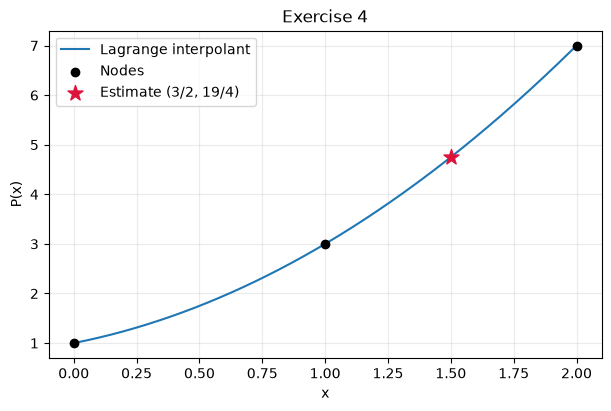

In [54]:
points = normalized["Exercises 4 and 7"]
target = sp.Rational(3, 2)
polynomial, bases = lagrange_polynomial(points)
estimate = sp.simplify(polynomial.subs(x_symbol, target))
direct = lagrange_evaluate(points, target)
assert estimate == direct
basis_table = pd.DataFrame({"Basis": [f"L_{i}(x)" for i in range(len(bases))], "Expression": list(map(str, bases))})
display(basis_table)
display(pd.DataFrame([{"Interpolant P(x)": str(polynomial), "Target x": str(target), "Estimate": str(estimate), "Direct check": str(direct)}]))

x_values = np.linspace(0, 2, 250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(polynomial.subs(x_symbol, value)) for value in x_values], label="Lagrange interpolant")
ax.scatter(*zip(*points), color="black", label="Nodes", zorder=3)
ax.scatter([float(target)], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 4", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 5: Lagrange interpolation

For the nodes $(0,2)$, $(1,5)$, and $(2,4)$, construct the basis polynomials and the interpolant. Estimate the function value at $x=1.5$.

,Basis,Expression
0,L_0(x),(x - 2)*(x - 1)/2
1,L_1(x),-x*(x - 2)
2,L_2(x),x*(x - 1)/2


,Interpolant P(x),Target x,Estimate,Direct check
0,-2*x**2 + 5*x + 2,3/2,5,5


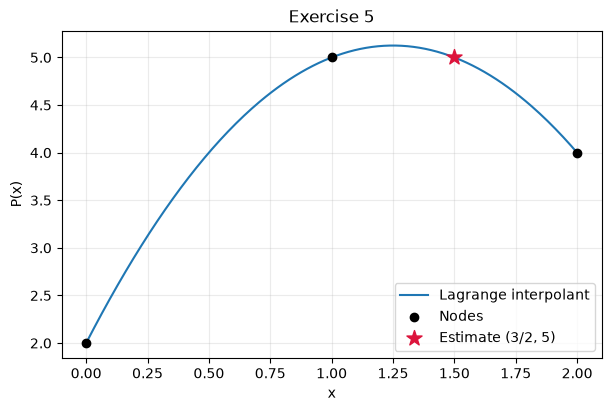

In [55]:
points = normalized["Exercises 5 and 8"]
target = sp.Rational(3, 2)
polynomial, bases = lagrange_polynomial(points)
estimate = sp.simplify(polynomial.subs(x_symbol, target))
direct = lagrange_evaluate(points, target)
assert estimate == direct
basis_table = pd.DataFrame({"Basis": [f"L_{i}(x)" for i in range(len(bases))], "Expression": list(map(str, bases))})
display(basis_table)
display(pd.DataFrame([{"Interpolant P(x)": str(polynomial), "Target x": str(target), "Estimate": str(estimate), "Direct check": str(direct)}]))

x_values = np.linspace(0, 2, 250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(polynomial.subs(x_symbol, value)) for value in x_values], label="Lagrange interpolant")
ax.scatter(*zip(*points), color="black", label="Nodes", zorder=3)
ax.scatter([float(target)], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 5", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 6: Lagrange interpolation

For the nodes $(0,3)$, $(1,2)$, and $(3,6)$, construct the basis polynomials and the interpolant. Estimate the function value at $x=2$.

,Basis,Expression
0,L_0(x),(x - 3)*(x - 1)/3
1,L_1(x),-x*(x - 3)/2
2,L_2(x),x*(x - 1)/6


,Interpolant P(x),Target x,Estimate,Direct check
0,x**2 - 2*x + 3,2,3,3


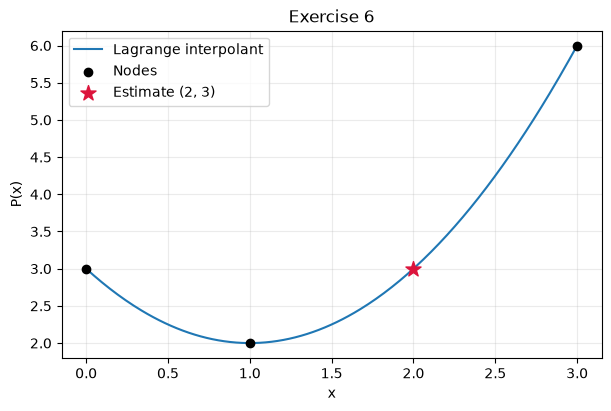

In [56]:
points = normalized["Exercises 6 and 9"]
target = 2
polynomial, bases = lagrange_polynomial(points)
estimate = sp.simplify(polynomial.subs(x_symbol, target))
direct = lagrange_evaluate(points, target)
assert estimate == direct
basis_table = pd.DataFrame({"Basis": [f"L_{i}(x)" for i in range(len(bases))], "Expression": list(map(str, bases))})
display(basis_table)
display(pd.DataFrame([{"Interpolant P(x)": str(polynomial), "Target x": target, "Estimate": str(estimate), "Direct check": str(direct)}]))

x_values = np.linspace(0, 3, 250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(polynomial.subs(x_symbol, value)) for value in x_values], label="Lagrange interpolant")
ax.scatter(*zip(*points), color="black", label="Nodes", zorder=3)
ax.scatter([target], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 6", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 7: Newton divided differences

For the nodes $(0,1)$, $(1,3)$, and $(2,7)$, build the divided-difference table and Newton polynomial. Estimate at $x=1.5$ and compare with Exercise 4.

,Exercise,x,f[x],Order 1,Order 2
0,Exercise 7,0,1,2,1
1,Exercise 7,1,3,4,
2,Exercise 7,2,7,,


,Newton polynomial,Estimate,Direct check,Matches Exercise 4
0,x**2 + x + 1,19/4,19/4,True


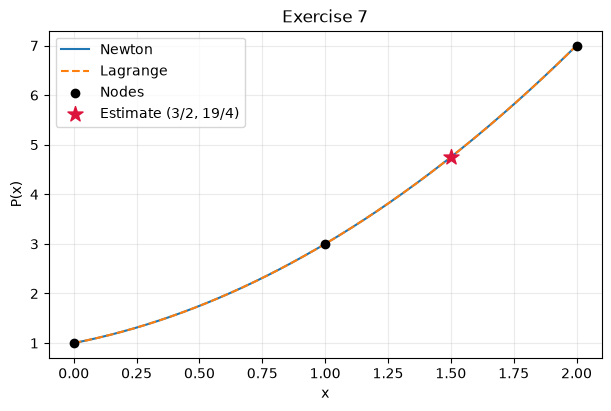

In [57]:
points = datasets["Exercises 4 and 7"]
target = sp.Rational(3, 2)
polynomial, table = newton_polynomial(points)
estimate = sp.simplify(polynomial.subs(x_symbol, target))
direct = newton_evaluate(points, target)
lagrange_fit, _ = lagrange_polynomial(points)
assert estimate == direct
assert sp.simplify(polynomial - lagrange_fit) == 0
display_difference_table("Exercise 7", points, table)
display(pd.DataFrame([{"Newton polynomial": str(polynomial), "Estimate": str(estimate), "Direct check": str(direct), "Matches Exercise 4": True}]))

x_values = np.linspace(0, 2, 250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(polynomial.subs(x_symbol, value)) for value in x_values], label="Newton")
ax.plot(x_values, [float(lagrange_fit.subs(x_symbol, value)) for value in x_values], linestyle="--", label="Lagrange")
ax.scatter(*zip(*points), color="black", label="Nodes", zorder=3)
ax.scatter([float(target)], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 7", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 8: Newton divided differences

For the nodes $(0,2)$, $(1,5)$, and $(2,4)$, build the divided-difference table and Newton polynomial. Estimate at $x=1.5$ and compare with Exercise 5.

,Exercise,x,f[x],Order 1,Order 2
0,Exercise 8,0,2,3,-2
1,Exercise 8,1,5,-1,
2,Exercise 8,2,4,,


,Newton polynomial,Estimate,Direct check,Matches Exercise 5
0,-2*x**2 + 5*x + 2,5,5,True


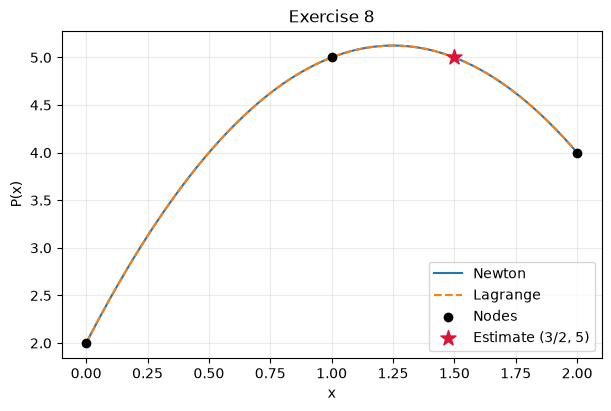

In [43]:
points = datasets["Exercises 5 and 8"]
target = sp.Rational(3, 2)
polynomial, table = newton_polynomial(points)
estimate = sp.simplify(polynomial.subs(x_symbol, target))
direct = newton_evaluate(points, target)
lagrange_fit, _ = lagrange_polynomial(points)
assert estimate == direct
assert sp.simplify(polynomial - lagrange_fit) == 0
display_difference_table("Exercise 8", points, table)
display(pd.DataFrame([{"Newton polynomial": str(polynomial), "Estimate": str(estimate), "Direct check": str(direct), "Matches Exercise 5": True}]))

x_values = np.linspace(0, 2, 250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(polynomial.subs(x_symbol, value)) for value in x_values], label="Newton")
ax.plot(x_values, [float(lagrange_fit.subs(x_symbol, value)) for value in x_values], linestyle="--", label="Lagrange")
ax.scatter(*zip(*points), color="black", label="Nodes", zorder=3)
ax.scatter([float(target)], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 8", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 9: Newton divided differences

For the nodes $(0,3)$, $(1,2)$, and $(3,6)$, build the divided-difference table and Newton polynomial. Estimate at $x=2$ and compare with Exercise 6.

,Exercise,x,f[x],Order 1,Order 2
0,Exercise 9,0,3,-1,1
1,Exercise 9,1,2,2,
2,Exercise 9,3,6,,


,Newton polynomial,Estimate,Direct check,Matches Exercise 6
0,x**2 - 2*x + 3,3,3,True


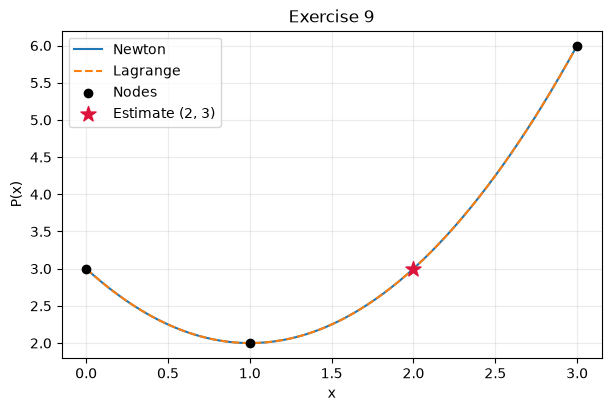

In [45]:
points = datasets["Exercises 6 and 9"]
target = 2
polynomial, table = newton_polynomial(points)
estimate = sp.simplify(polynomial.subs(x_symbol, target))
direct = newton_evaluate(points, target)
lagrange_fit, _ = lagrange_polynomial(points)
assert estimate == direct
assert sp.simplify(polynomial - lagrange_fit) == 0
display_difference_table("Exercise 9", points, table)
display(pd.DataFrame([{"Newton polynomial": str(polynomial), "Estimate": str(estimate), "Direct check": str(direct), "Matches Exercise 6": True}]))

x_values = np.linspace(0, 3, 250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(polynomial.subs(x_symbol, value)) for value in x_values], label="Newton")
ax.plot(x_values, [float(lagrange_fit.subs(x_symbol, value)) for value in x_values], linestyle="--", label="Lagrange")
ax.scatter(*zip(*points), color="black", label="Nodes", zorder=3)
ax.scatter([target], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 9", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 10: Cubic interpolation

For the nodes $(0,0)$, $(1,1)$, $(2,8)$, and $(3,27)$, construct the Lagrange basis polynomials and Newton divided-difference table. Evaluate both forms at $x=1.5$, verify the node values, and identify the function represented by the data. Then increase $y(2)$ by one as a hypothetical measurement error and examine its effect on the estimate.

,Basis,Expression
0,L_0(x),-(x - 3)*(x - 2)*(x - 1)/6
1,L_1(x),x*(x - 3)*(x - 2)/2
2,L_2(x),-x*(x - 3)*(x - 1)/2
3,L_3(x),x*(x - 2)*(x - 1)/6


,Exercise,x,f[x],Order 1,Order 2,Order 3
0,Exercise 10,0,0,1,3,1
1,Exercise 10,1,1,7,6,
2,Exercise 10,2,8,19,,
3,Exercise 10,3,27,,,


,Lagrange polynomial,Newton polynomial,Estimate at x=1.5,Both pass through all nodes
0,x**3,x**3,27/8,True


The underlying function is f(x) = x^3.
If y(2) increases by one, the interpolant changes by: -x*(x - 3)*(x - 1)/2
The estimate at x=1.5 changes by: 9/16


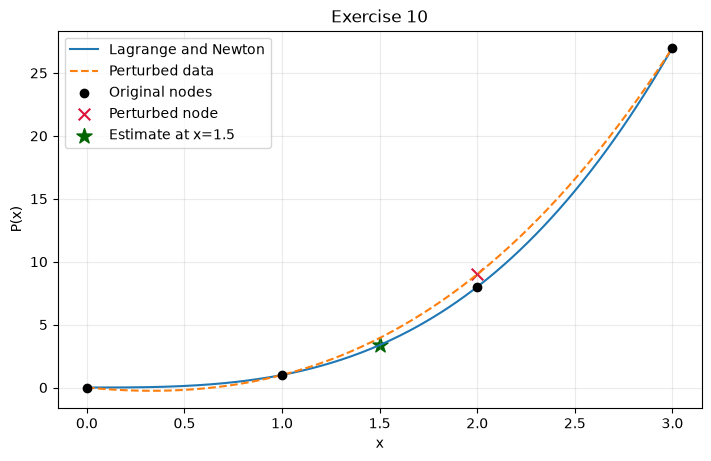

In [58]:
points10 = datasets["Exercise 10"]
lagrange10, bases10 = lagrange_polynomial(points10)
newton10, table10 = newton_polynomial(points10)
target10 = sp.Rational(3, 2)
lagrange_estimate10 = sp.simplify(lagrange10.subs(x_symbol, target10))
newton_estimate10 = sp.simplify(newton10.subs(x_symbol, target10))
assert sp.simplify(lagrange10 - newton10) == 0
assert lagrange_estimate10 == newton_estimate10 == sp.Rational(27, 8)
assert lagrange_evaluate(points10, target10) == lagrange_estimate10
assert newton_evaluate(points10, target10) == newton_estimate10
assert all(sp.simplify(lagrange10.subs(x_symbol, x) - y) == 0 for x, y in rational_points(points10))
assert all(sp.simplify(newton10.subs(x_symbol, x) - y) == 0 for x, y in rational_points(points10))

basis_table = pd.DataFrame({"Basis": [f"L_{i}(x)" for i in range(len(bases10))], "Expression": list(map(str, bases10))})
display(basis_table)
display_difference_table("Exercise 10", points10, table10)
display(pd.DataFrame([{"Lagrange polynomial": str(lagrange10), "Newton polynomial": str(newton10), "Estimate at x=1.5": str(lagrange_estimate10), "Both pass through all nodes": True}]))
print("The underlying function is f(x) = x^3.")

perturbed_points10 = [(x, y + 1 if x == 2 else y) for x, y in points10]
perturbed10, _ = lagrange_polynomial(perturbed_points10)
measurement_effect = sp.factor(perturbed10 - lagrange10)
perturbed_estimate = sp.simplify(perturbed10.subs(x_symbol, target10))
print("If y(2) increases by one, the interpolant changes by:", measurement_effect)
print("The estimate at x=1.5 changes by:", sp.simplify(perturbed_estimate - lagrange_estimate10))

x_values = np.linspace(0, 3, 300)
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.plot(x_values, [float(lagrange10.subs(x_symbol, value)) for value in x_values], label="Lagrange and Newton")
ax.plot(x_values, [float(perturbed10.subs(x_symbol, value)) for value in x_values], linestyle="--", label="Perturbed data")
ax.scatter(*zip(*points10), color="black", label="Original nodes", zorder=3)
ax.scatter([2], [9], marker="x", color="crimson", s=70, label="Perturbed node")
ax.scatter([1.5], [float(lagrange_estimate10)], marker="*", color="darkgreen", s=130, label="Estimate at x=1.5")
ax.set(title="Exercise 10", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Exercise 11: Incremental Newton update

Add $(3,10)$ to the nodes from Exercise 7. Update the divided-difference table and polynomial with the new term, estimate at $x=1.5$, and compare the three-node and four-node interpolants. Newton retains its previous coefficients; the Lagrange basis polynomials would need to be rebuilt.

For this dataset, the added term is $-\frac{1}{2}x(x-1)(x-2)$, giving $P_4(1.5)=\frac{79}{16}$.

,Exercise,x,f[x],Order 1,Order 2,Order 3
0,Exercise 11,0,1,2,1,-1/2
1,Exercise 11,1,3,4,-1/2,
2,Exercise 11,2,7,3,,
3,Exercise 11,3,10,,,


,Original P_3(x),Added coefficient,Added term,Updated P_4(x),Estimate at x=1.5,Previous coefficients preserved
0,x**2 + x + 1,-1/2,-x*(x - 2)*(x - 1)/2,-x**3/2 + 5*x**2/2 + 1,79/16,True


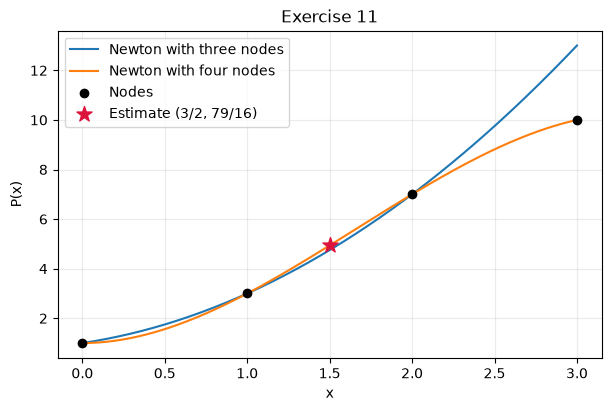

In [59]:
original_points = datasets["Exercises 4 and 7"]
updated_points = datasets["Exercise 11"]
original_exact, original_table = divided_difference_table(original_points)
original_polynomial, _ = newton_polynomial(original_points)
new_x, new_y = rational_points([updated_points[-1]])[0]
node_count = len(original_exact)

new_column = [new_y]
for order in range(1, node_count + 1):
    row = node_count - order
    previous_difference = original_table[row][order - 1]
    new_column.append(sp.simplify(
        (new_column[-1] - previous_difference) / (new_x - original_exact[row][0])
    ))

new_coefficient = new_column[-1]
added_term = sp.factor(new_coefficient * sp.prod(x_symbol - x_i for x_i, _ in original_exact))
updated_polynomial = sp.expand(original_polynomial + added_term)
updated_table = [[None] * (node_count + 1) for _ in range(node_count + 1)]
for row in range(node_count):
    for order in range(node_count - row):
        updated_table[row][order] = original_table[row][order]
for order, difference in enumerate(reversed(new_column)):
    updated_table[order][node_count - order] = difference

target = sp.Rational(3, 2)
estimate = sp.simplify(updated_polynomial.subs(x_symbol, target))
assert new_column == [sp.Integer(10), sp.Integer(3), sp.Rational(-1, 2), sp.Rational(-1, 2)]
assert updated_table[0][:node_count] == original_table[0][:node_count]
assert added_term == -x_symbol * (x_symbol - 1) * (x_symbol - 2) / 2
assert estimate == sp.Rational(79, 16)
assert all(sp.simplify(updated_polynomial.subs(x_symbol, x) - y) == 0 for x, y in rational_points(updated_points))

display_difference_table("Exercise 11", updated_points, updated_table)
display(pd.DataFrame([{"Original P_3(x)": str(original_polynomial), "Added coefficient": str(new_coefficient), "Added term": str(added_term), "Updated P_4(x)": str(updated_polynomial), "Estimate at x=1.5": str(estimate), "Previous coefficients preserved": True}]))

x_values = np.linspace(0, 3, 250)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(x_values, [float(original_polynomial.subs(x_symbol, value)) for value in x_values], label="Newton with three nodes")
ax.plot(x_values, [float(updated_polynomial.subs(x_symbol, value)) for value in x_values], label="Newton with four nodes")
ax.scatter(*zip(*updated_points), color="black", label="Nodes", zorder=3)
ax.scatter([float(target)], [float(estimate)], marker="*", s=130, color="crimson", label=f"Estimate ({target}, {estimate})", zorder=4)
ax.set(title="Exercise 11", xlabel="x", ylabel="P(x)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()